接下来将进行POS模拟预测，其中2012-2024年的数据用于拟合模型的因子beta值，2025-2026年将使用预测+回归的循环模式，逐步更新模型的参数以及检验模型的回归性能。其中，2025-2026的预测与回归将在下一个笔记本中进行。

Next, a POS simulation forecast will be conducted. Data from 2012–2024 will be used to estimate the model’s factor beta values, while 2025–2026 will use a recursive “prediction + regression” loop to progressively update the model parameters and evaluate the model’s regression performance. Among them, the predictions and regressions for the period 2025-2026 will be presented in the next notebook.


In [1]:
# First, import packages
import pandas as pd
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.multitest import multipletests

下面读取 `data/3_POS_prediction/` 中的日度汇率、五个宏观因子和政策事件，估计截至 2024-12-31 的初始模型。

在完整日历上生成汇率变化率的一日滞后，再提取共同非缺失样本。五个宏观因子使用当日采用值，保留原单位。三个年度文件中的 `is_prediction` 保存为来源标记，本次回归沿用第 6 个笔记本的五因子结构。常数事件列不入模，完全相同的事件列共用一个系数；不同日期的事件分别保留。

This section reads daily FX changes, five macro factors, and policy events from `data/3_POS_prediction/` to estimate the initial model through 2024-12-31.

The one-day FX lag is constructed on the full daily calendar before selecting complete observations. Macro factors use their same-day adopted values and retain their existing units. The annual `is_prediction` columns are kept as source flags and are excluded from this five-factor specification. Constant event columns are omitted, identical event columns share a coefficient, and events on different dates remain separate.


In [2]:
DATA = Path("data/3_POS_prediction")
if not DATA.is_dir():
    DATA = Path("../data/3_POS_prediction")
if not DATA.is_dir():
    raise FileNotFoundError("Run this notebook from the project root or notebook directory.")

TRAIN_START, TRAIN_END = "2012-01-01", "2024-12-31"
# Retain Sunday through Thursday; lags and HAC(12) count retained observations.
MODEL_DAY = pd.offsets.CustomBusinessDay(weekmask="Sun Mon Tue Wed Thu")
calendar = pd.date_range(TRAIN_START, TRAIN_END, freq=MODEL_DAY)
FACTOR_FILES = {
    "CPI": "headline_cpi_log_change_daily.csv",
    "GDP growth change": "gdp_annual_pct_change_daily.csv",
    "Trade balance change": "trade_balance_annual_pct_change_daily.csv",
    "FX reserves": "fx_reserves_log_change_daily.csv",
    "Government debt / GDP": "general_government_gross_debt_annual_change_pp_daily.csv",
}
factors = list(FACTOR_FILES)

def read_daily(filename):
    frame = pd.read_csv(DATA / filename)
    frame.index = pd.to_datetime(frame.pop("date"), format="%Y/%m/%d")
    if frame.index.has_duplicates or not frame.index.is_monotonic_increasing:
        raise ValueError(f"Dates must be unique and increasing: {filename}")
    if not calendar.isin(frame.index).all():
        raise ValueError(f"Missing training-calendar dates: {filename}")
    # Reindex to the training period before constructing any model input.
    return frame.reindex(calendar).apply(pd.to_numeric, errors="raise")

factor_frames = {name: read_daily(filename) for name, filename in FACTOR_FILES.items()}
macro = pd.DataFrame({name: frame.iloc[:, 0] for name, frame in factor_frames.items()})
prediction_flags = pd.DataFrame({
    name: frame["is_prediction"]
    for name, frame in factor_frames.items()
    if "is_prediction" in frame.columns
})
fx = read_daily("USDSLE_daily.csv").iloc[:, 0].rename("fx_change")
events = read_daily("Sierra_Leone_Policy_Event_Dummies_daily.csv")
sample = pd.concat(
    [fx, fx.shift(1).rename("fx_lag1"), macro, events], axis=1
).dropna()

# Preserve separate daily event pulses, including the two events in August 2021.
groups = {}
for name in events:
    values = sample[name]
    if values.nunique() > 1:
        groups.setdefault(tuple(values), []).append(name)
policy_X = pd.DataFrame(index=sample.index, dtype=float)
policy_sources = {}
for pattern, names in groups.items():
    event_date = sample.index[np.asarray(pattern) == 1][0]
    term = f"P_{event_date:%Y_%m_%d}"
    if term in policy_X:
        raise ValueError(f"Distinct event patterns share a term name: {term}")
    policy_X[term] = np.asarray(pattern, dtype=float)
    policy_sources[term] = " + ".join(names)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")
sample_summary = pd.DataFrame({
    "requested_start": [TRAIN_START],
    "training_end": [TRAIN_END],
    "sample_start": [sample.index.min().strftime("%Y-%m-%d")],
    "sample_end": [sample.index.max().strftime("%Y-%m-%d")],
    "observation_days": [len(calendar)],
    "complete_days": [len(sample)],
    "excluded_days": [len(calendar) - len(sample)],
    "macro_factors": [len(factors)],
    "event_terms": [policy_X.shape[1]],
}, index=["Daily training sample"])
display(sample_summary)


,requested_start,training_end,sample_start,sample_end,observation_days,complete_days,excluded_days,macro_factors,event_terms
Daily training sample,2012-01-01,2024-12-31,2013-06-18,2024-12-31,3393,3011,382,5,6


下面估计“日度汇率变化率＝截距＋滞后一天的汇率变化率＋五个同期宏观因子＋事件项＋残差”，并列出回归指标、连续项系数、五因子联合结果及事件系数。

设置与假设：

- OLS 估计系数；`alpha=0.05`，采用 HAC(12) 标准误、Bartlett 权重、有限样本修正和渐近正态 z 检验。本次数据为日度，12 表示 12 个日度滞后。
- 单项原假设为系数等于 0。五个宏观因子的 p 值使用 Holm 校正，截距与 AR 项使用未校正 p 值；置信区间为逐项 95% 区间。
- 联合原假设为五个宏观因子系数同时等于 0，使用 HAC Wald 检验。
- 单日事件项会使对应日期的拟合残差接近 0，因此事件项只报告系数和事件日期，不报告显著性。
- R²、调整后 R² 和 RMSE 均为样本内指标。此次仅完成初始回归，不重复单位根、共线性或残差诊断检验。
- 本模型沿用截图的同期因子设定。结果用于初始拟合；后续 POS 仍需按预测时点限制可用信息。源文件已有的历史预测版本及日期假设继续适用。

The model is daily FX change = intercept + one-day lagged FX change + five contemporaneous macro factors + event terms + residual. The outputs report fit statistics, continuous-term coefficients, the joint macro-factor test, and event coefficients.

Settings and hypotheses:

- Coefficients are estimated by OLS. Inference uses `alpha=0.05`, HAC(12) standard errors, Bartlett weights, a finite-sample correction, and asymptotic normal z-tests. Here, 12 refers to daily lags.
- Individual null hypotheses set each coefficient to zero. Holm correction applies to the five macro-factor p-values; the intercept and AR term use unadjusted p-values. Confidence intervals are individual 95% intervals.
- The joint HAC Wald test sets all five macro coefficients to zero.
- A single-day event term makes its date's fitted residual approximately zero. Event results therefore report coefficients and dates without significance tests.
- R², adjusted R², and RMSE are in-sample measures. This section estimates the initial regression without repeating unit-root, collinearity, or residual diagnostic tests.
- The contemporaneous-factor specification follows the supplied example. Later POS predictions still require information available at each forecast origin. The source files' historical-vintage and date assumptions remain applicable.


In [3]:
# Estimate OLS coefficients and reproduce the reference HAC inference.
ALPHA, HAC_LAGS = 0.05, 12
continuous = ["fx_lag1", *factors]
y = sample["fx_change"]
X = sm.add_constant(
    pd.concat([sample[continuous], policy_X], axis=1),
    has_constant="add",
)
ols = sm.OLS(y, X).fit()
hac = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": HAC_LAGS, "kernel": "bartlett", "use_correction": True},
    use_t=False,
)

fit_summary = pd.DataFrame({
    "n": [int(ols.nobs)],
    "parameters": [len(ols.params)],
    "R2": [ols.rsquared],
    "adjusted_R2": [ols.rsquared_adj],
    "RMSE": [np.sqrt(np.mean(ols.resid ** 2))],
}, index=["Daily AR(1) + five factors + events"])
display(fit_summary)

terms = ["const", *continuous]
ci = hac.conf_int(alpha=ALPHA).loc[terms]
coefficient_table = pd.DataFrame({
    "coefficient": hac.params.loc[terms],
    "HAC_SE": hac.bse.loc[terms],
    "z": hac.tvalues.loc[terms],
    "p_HAC": hac.pvalues.loc[terms],
    "CI95_low": ci[0],
    "CI95_high": ci[1],
})
coefficient_table["p_Holm_5_factors"] = np.nan
coefficient_table.loc[factors, "p_Holm_5_factors"] = multipletests(
    coefficient_table.loc[factors, "p_HAC"], method="holm"
)[1]
coefficient_table["reject_5pct"] = coefficient_table["p_HAC"] < ALPHA
coefficient_table.loc[factors, "reject_5pct"] = (
    coefficient_table.loc[factors, "p_Holm_5_factors"] < ALPHA
)
display(coefficient_table)

R = np.eye(X.shape[1])[[X.columns.get_loc(name) for name in factors]]
joint = hac.wald_test(R, use_f=False, scalar=True)
joint_table = pd.DataFrame({
    "chi2": [float(joint.statistic)],
    "df": [len(factors)],
    "p_HAC": [float(joint.pvalue)],
    "reject_5pct": [bool(joint.pvalue < ALPHA)],
}, index=["All five macro coefficients = 0"])
display(joint_table)

policy_table = pd.DataFrame({
    "source_events": pd.Series(policy_sources),
    "coefficient": ols.params.loc[policy_X.columns],
    "date": [
        policy_X.index[policy_X[name].eq(1)][0].strftime("%Y-%m-%d")
        for name in policy_X
    ],
})
display(policy_table)


,n,parameters,R2,adjusted_R2,RMSE
Daily AR(1) + five factors + events,3011,13,0.306083,0.303306,1.05849


,coefficient,HAC_SE,z,p_HAC,CI95_low,CI95_high,p_Holm_5_factors,reject_5pct
const,-0.00321814,0.0166526,-0.193252,0.846762,-0.0358566,0.0294203,NaN,False
fx_lag1,-0.0841899,0.0343495,-2.45098,0.0142469,-0.151514,-0.0168661,NaN,True
CPI,0.0214324,0.0156542,1.36911,0.170965,-0.00924937,0.0521141,0.683859,False
GDP growth change,0.000262877,9.37834e-05,2.80302,0.0050626,7.9065e-05,0.000446689,0.025313,True
Trade balance change,-6.62096e-05,0.000122852,-0.538936,0.589931,-0.000306996,0.000174576,1,False
FX reserves,0.000722106,0.00210564,0.342939,0.731644,-0.00340487,0.00484908,1,False
Government debt / GDP,0.00372942,0.0036984,1.00839,0.313269,-0.00351932,0.0109782,0.939807,False


,chi2,df,p_HAC,reject_5pct
All five macro coefficients = 0,13.986,5,0.0156988,True


,source_events,coefficient,date
P_2015_11_16,D_IMF_ECF_REVIEW_2015,-0.16528,2015-11-16
P_2016_06_23,D_Brexit referendum_2016,38.6412,2016-06-23
P_2021_08_12,D_REDENOM_ANNOUNCE_2021,0.0703092,2021-08-12
P_2021_08_23,D_SDR_ALLOCATION_2021,0.000369572,2021-08-23
P_2023_06_05,D_IMF_ECF_REVIEW_A_2023,-0.133449,2023-06-05
P_2023_11_20,D_IMF_ECF_REVIEW_B_2023,-0.48394,2023-11-20


下面绘制训练样本的三张图：实际与拟合汇率变化率、逐日残差，以及全部残差的分布。残差按“实际值－拟合值”计算，横线与竖线标出 0。所有图仅使用截至 2024-12-31 的回归样本，拟合线表示样本内结果。

The following plots show observed and fitted FX changes, daily residuals, and the distribution of all residuals. Residuals are observed values minus fitted values, with reference lines at zero. All plots use only the regression sample through 2024-12-31; the fitted line is an in-sample result.


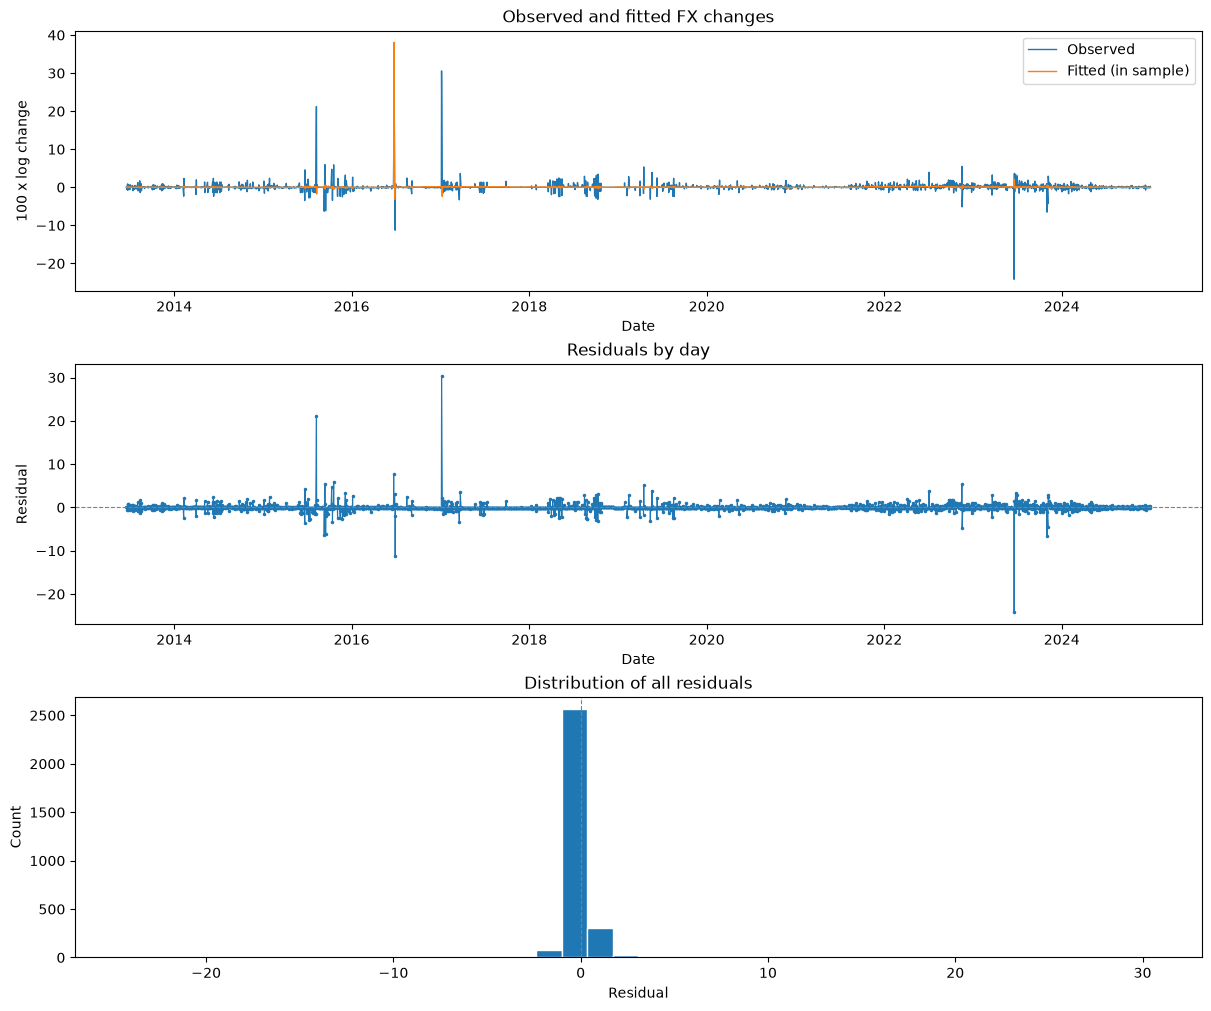

In [4]:
# Plot the fitted daily changes and residuals without exporting separate files.
fitted = ols.fittedvalues
plot_residuals = ols.resid
fig, axes = plt.subplots(3, 1, figsize=(12, 10), layout="constrained")

axes[0].plot(y.index, y, label="Observed", linewidth=1)
axes[0].plot(fitted.index, fitted, label="Fitted (in sample)", linewidth=1)
axes[0].set(
    title="Observed and fitted FX changes",
    xlabel="Date",
    ylabel="100 x log change",
)
axes[0].legend()

axes[1].plot(
    plot_residuals.index, plot_residuals, marker=".", markersize=3,
    linewidth=0.8, color="tab:blue",
)
axes[1].axhline(0, color="grey", linestyle="--", linewidth=0.8)
axes[1].set(title="Residuals by day", xlabel="Date", ylabel="Residual")

axes[2].hist(plot_residuals, bins=40, color="tab:blue", edgecolor="white")
axes[2].axvline(0, color="grey", linestyle="--", linewidth=0.8)
axes[2].set(title="Distribution of all residuals", xlabel="Residual", ylabel="Count")
plt.show()


**下面单独估计仅含 `const` 和 `fx_lag1` 的 AR(1) 基准模型，并与上面的五因子加事件模型比较。**

训练窗口仍为 2012-01-01 至 2024-12-31。为保证比较使用相同日期和相同因变量，基准模型直接使用上面已经形成的 `y`，设计矩阵取 `X` 的 `const`、`fx_lag1` 两列。

两者均采用 OLS 系数和 HAC(12) 推断，设置为 Bartlett 权重、有限样本修正、渐近正态 z 检验。下面列出 R²、调整后 R²、RMSE、MAE、AIC、BIC，以及两个共同系数的 HAC p 值和 95% 区间。

**This section separately estimates an AR(1) benchmark containing only `const` and `fx_lag1`, then compares it with the five-factor-plus-events model above.**

The requested training window remains 2012-01-01 through 2024-12-31. Both models use exactly the same response `y` and dates. The benchmark design matrix selects only `const` and `fx_lag1` from the existing `X`. 

Both models use OLS coefficients and HAC(12) inference with Bartlett weights, finite-sample correction, and asymptotic normal z-tests. The tables report R², adjusted R², RMSE, MAE, AIC, BIC, and HAC p-values and 95% intervals for the shared coefficients. 


In [5]:
# Fit the two-parameter benchmark on exactly the full model's training sample.
benchmark_y = y.copy()
benchmark_X = X.loc[:, ["const", "fx_lag1"]].copy()
benchmark_ols = sm.OLS(benchmark_y, benchmark_X).fit()
benchmark_hac = sm.OLS(benchmark_y, benchmark_X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": HAC_LAGS, "kernel": "bartlett", "use_correction": True},
    use_t=False,
)

# Fit AR(1) plus the same event dummies on the common sample, without macro factors.
event_benchmark_X = X.loc[:, ["const", "fx_lag1", *policy_X.columns]].copy()
event_benchmark_ols = sm.OLS(benchmark_y, event_benchmark_X).fit()
event_benchmark_hac = sm.OLS(benchmark_y, event_benchmark_X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": HAC_LAGS, "kernel": "bartlett", "use_correction": True},
    use_t=False,
)

# Keep the existing full-model objects unchanged.
comparison_models = {
    "AR(1) benchmark": (benchmark_ols, benchmark_hac),
    "AR(1) + events": (event_benchmark_ols, event_benchmark_hac),
    "AR(1) + five factors + events": (ols, hac),
}
model_comparison = pd.DataFrame({
    name: {
        "sample_start": benchmark_y.index.min().strftime("%Y-%m-%d"),
        "sample_end": benchmark_y.index.max().strftime("%Y-%m-%d"),
        "n": int(fit.nobs),
        "parameters": len(fit.params),
        "R2": fit.rsquared,
        "adjusted_R2": fit.rsquared_adj,
        "RMSE": np.sqrt(np.mean(fit.resid ** 2)),
        "MAE": np.mean(np.abs(fit.resid)),
        "AIC": fit.aic,
        "BIC": fit.bic,
    }
    for name, (fit, robust_fit) in comparison_models.items()
}).T
display(model_comparison)

comparison_shared_terms = ["const", "fx_lag1"]
comparison_coefficient_tables = {}
for name, (fit, robust_fit) in comparison_models.items():
    comparison_ci = robust_fit.conf_int(alpha=ALPHA).loc[comparison_shared_terms]
    comparison_coefficient_tables[name] = pd.DataFrame({
        "coefficient": robust_fit.params.loc[comparison_shared_terms],
        "HAC_SE": robust_fit.bse.loc[comparison_shared_terms],
        "z": robust_fit.tvalues.loc[comparison_shared_terms],
        "p_HAC": robust_fit.pvalues.loc[comparison_shared_terms],
        "CI95_low": comparison_ci[0],
        "CI95_high": comparison_ci[1],
        "reject_5pct": robust_fit.pvalues.loc[comparison_shared_terms] < ALPHA,
    })
benchmark_coefficient_comparison = pd.concat(
    comparison_coefficient_tables, names=["model", "term"]
)
display(benchmark_coefficient_comparison)

# This is the existing conditional macro-factor test, not a test of all added terms.
comparison_macro_joint = joint_table.copy()
comparison_macro_joint.index = [
    "Full model: five macro coefficients = 0, controlling for AR(1) and events"
]
display(comparison_macro_joint)


,sample_start,sample_end,n,parameters,R2,adjusted_R2,RMSE,MAE,AIC,BIC
AR(1) benchmark,2013-06-18,2024-12-31,3011,2,0.000442634,0.000110444,1.27039,0.342254,9990.07,10002.1
AR(1) + events,2013-06-18,2024-12-31,3011,8,0.303585,0.301962,1.0604,0.326496,8913.99,8962.07
AR(1) + five factors + events,2013-06-18,2024-12-31,3011,13,0.306083,0.303306,1.05849,0.327797,8913.17,8991.3


coefficient    HAC_SE         z  \
model                         term                                       
AR(1) benchmark               const      0.0565804 0.0183847   3.07758   
                              fx_lag1   -0.0210389   0.07043  -0.29872   
AR(1) + events                const      0.0473948 0.0170623   2.77775   
                              fx_lag1   -0.0819359  0.034093   -2.4033   
AR(1) + five factors + events const    -0.00321814 0.0166526 -0.193252   
                              fx_lag1   -0.0841899 0.0343495  -2.45098   

                                           p_HAC   CI95_low  CI95_high  \
model                         term                                       
AR(1) benchmark               const   0.00208687  0.0205471  0.0926137   
                              fx_lag1   0.765154  -0.159079   0.117001   
AR(1) + events                const    0.0054736  0.0139534  0.0808363   
                              fx_lag1  0.0162477  -0.148757 -0.0151148   
AR(1) + five factors + events const     0.846762 -0.0358566  0.0294203   
                              fx_lag1  0.0142469  -0.151514 -0.0168661   

                                       reject_5pct  
model                         term                  
AR(1) benchmark               const           True  
                              fx_lag1        False  
AR(1) + events                const           True  
                              fx_lag1         True  
AR(1) + five factors + events const          False  
                              fx_lag1         True

,chi2,df,p_HAC,reject_5pct
"Full model: five macro coefficients = 0, controlling for AR(1) and events",13.986,5,0.0156988,True


**回归分析 | Regression Analysis** 

相比于第二次回归，在消除未来函数（也就是looks ahead bias）之后，使用IMF预测数据和滞后的实际数据进行回归的实际解释程度有所下降，Rs和adj. Rs仅有约30%。p值方面，GDP和一阶之后fx数据具有较强的解释力，而其余解释力都不足。但是作为整体，p值小于0.05。对比来看，模型整体相比AR(1)模型有提升，但是相对于AR(1)+events模型来说几乎没有提升。

Compared to the second regression, after eliminating the look-ahead bias (by using IMF forecast data and lagged actual data for the regression), the actual explanatory power has decreased, with the Rs and adj. Rs standing at only about 30%. Regarding the p-values, GDP and the first-order lag of FX data exhibit strong explanatory power, whereas the remaining variables are insignificant. However, as a whole, the p-value is less than 0.05. Comparatively, while the model overall shows an improvement over the AR(1) model, it yields almost no improvement relative to the AR(1)+events model.